In [2]:
# import des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [3]:
# Récupération du dataset
df = pd.read_csv('data/2016-building-energy-benchmarking-6af870b7ba821669818300.csv')
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


# Exploration du dataset

In [4]:
# information sur les données et les types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [5]:
# Informations statistiques sur les colonnes numériques

df.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


In [6]:
# Informations sur les colonnes non numériques

df.describe(exclude=[np.number])

,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,YearsENERGYSTARCertified,DefaultData,ComplianceStatus,Outlier
count,3376,3376,3376,3376,3376,3376,3376,3376,3367,3356,1679,596,119,3376,3376,32
unique,8,24,3362,3354,1,1,3268,19,466,56,50,44,65,2,4,2
top,NonResidential,Low-Rise Multifamily,Northgate Plaza,2600 SW Barton St,Seattle,WA,1625049001,DOWNTOWN,Multifamily Housing,Multifamily Housing,Parking,Retail Store,2016,False,Compliant,Low outlier
freq,1460,987,3,4,3376,3376,8,573,866,1667,976,110,14,3263,3211,23


colonnes avec valeurs manquantes et propositions pour gérer ces données manquantes

 8   ZipCode                          3360 non-null   float64  --> récupération des ZipCodes manquants avec API longitude / latitude ?
 15  NumberofBuildings                3368 non-null   float64  --> moyenne et median autour de 1 ?
 20  ListOfAllPropertyUseTypes        3367 non-null   str      --> mettre "unknown ? supprimer les linges où ces informations sont manquantes ?  
 21  LargestPropertyUseType           3356 non-null   str      --> mettre le premier des ListOfAllPropertyUseType , si unknown --> unknown?
 22  LargestPropertyUseTypeGFA        3356 non-null   float64  --> moyenne / mediane / supprimer les linges où ces informations sont manquantes ? 
 23  SecondLargestPropertyUseType     1679 non-null   str      --> Absent = N/A?
 24  SecondLargestPropertyUseTypeGFA  1679 non-null   float64  --> absent = 0 ? 
 25  ThirdLargestPropertyUseType      596 non-null    str      --> Absent = N/A?
 26  ThirdLargestPropertyUseTypeGFA   596 non-null    float64  --> absent = 0 ? 
 27  YearsENERGYSTARCertified         119 non-null    object   --> suppression colonne?
 28  ENERGYSTARScore                  2533 non-null   float64  ==> déterminer interêt de ce score
 29  SiteEUI(kBtu/sf)                 3369 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 30  SiteEUIWN(kBtu/sf)               3370 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 31  SourceEUI(kBtu/sf)               3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 32  SourceEUIWN(kBtu/sf)             3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 33  SiteEnergyUse(kBtu)              3371 non-null   float64  ==> Créer modèle pour prédire l'énergie consommée (suppression des lignes avec cette colonne vide?)
 34  SiteEnergyUseWN(kBtu)            3370 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 35  SteamUse(kBtu)                   3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 36  Electricity(kWh)                 3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 37  Electricity(kBtu)                3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 38  NaturalGas(therms)               3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 39  NaturalGas(kBtu)                 3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)
 41  Comments                         0 non-null      float64  --> Vide , à drop
 43  Outlier                          32 non-null     str      --> Supprimer les outliers du dataset pour éviter d'influencer le modèle ?
 44  TotalGHGEmissions                3367 non-null   float64  ==> Créer modèle pour prédire l'énergie consommée (suppression des lignes avec cette colonne vide?)
 45  GHGEmissionsIntensity            3367 non-null   float64  --> on n'aura pas les données (pas mettre comme feature, à supprimer)

In [7]:
# Vérification des doublons
df.duplicated().sum()  

np.int64(0)

Il n'y a pas de doublons dans le dataset


les information qu'on ne pourra pas avoir sans relevés détaillés des propriétés 
On ne veut pas entraîner nos modèles dessus car on n'aura pas ces informations -- à drop:

 29  SiteEUI(kBtu/sf)                 3369 non-null   float64
 30  SiteEUIWN(kBtu/sf)               3370 non-null   float64
 31  SourceEUI(kBtu/sf)               3367 non-null   float64
 32  SourceEUIWN(kBtu/sf)             3367 non-null   float64
 34  SiteEnergyUseWN(kBtu)            3370 non-null   float64
 35  SteamUse(kBtu)                   3367 non-null   float64
 36  Electricity(kWh)                 3367 non-null   float64
 37  Electricity(kBtu)                3367 non-null   float64
 38  NaturalGas(therms)               3367 non-null   float64
 39  NaturalGas(kBtu)                 3367 non-null   float64   
 45  GHGEmissionsIntensity            3367 non-null   float64
dtypes: bool(1), float64(22), int64(8), object(1), str(14)
memory usage: 1.2+ MB


In [8]:
# Premier tri des colonnes : 
df_tri1 = df.drop(columns=['SiteEUI(kBtu/sf)','SiteEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'GHGEmissionsIntensity','SteamUse(kBtu)','Electricity(kWh)', 'Electricity(kBtu)','NaturalGas(therms)','NaturalGas(kBtu)'])

df_tri1.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEnergyUse(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,NaN,NaN,NaN,60.0,7226362.5,False,NaN,Compliant,NaN,249.98
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,Restaurant,4622.0,NaN,61.0,8387933.0,False,NaN,Compliant,NaN,295.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,NaN,NaN,NaN,43.0,72587024.0,False,NaN,Compliant,NaN,2089.28
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,NaN,NaN,NaN,56.0,6794584.0,False,NaN,Compliant,NaN,286.43
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,Swimming Pool,0.0,NaN,75.0,14172606.0,False,NaN,Compliant,NaN,505.01


In [20]:
# Analyse colonnes DataYear, Comments, City, State 

print("Valeur avec leur fréquence dans la colonne DataYear :")
print(df['DataYear'].value_counts())

print("Valeur avec leur fréquence dans la colonne City :")
print(df['City'].value_counts())

print("Valeur avec leur fréquence dans la colonne State :")
print(df['State'].value_counts())

print("Nombre de valeurs manquantes dans la colonne comments :")
print(df['Comments'].isna().sum())

# Ces colonnes ne sont pas pertinentes pour l'analyse. Les colonnes DataYear, State et City ne contiennt qu'une seule valeur et la colonne Comments ne contient que de valeurs manquantes.  
# --> on peut donc les supprimer.

df_tri2 = df_tri1.drop(columns=['DataYear', 'Comments', 'City', 'State'])

Valeur avec leur fréquence dans la colonne DataYear :
DataYear
2016    3376
Name: count, dtype: int64
Valeur avec leur fréquence dans la colonne City :
City
Seattle    3376
Name: count, dtype: int64
Valeur avec leur fréquence dans la colonne State :
State
WA    3376
Name: count, dtype: int64
Nombre de valeurs manquantes dans la colonne comments :
3376


<Axes: >

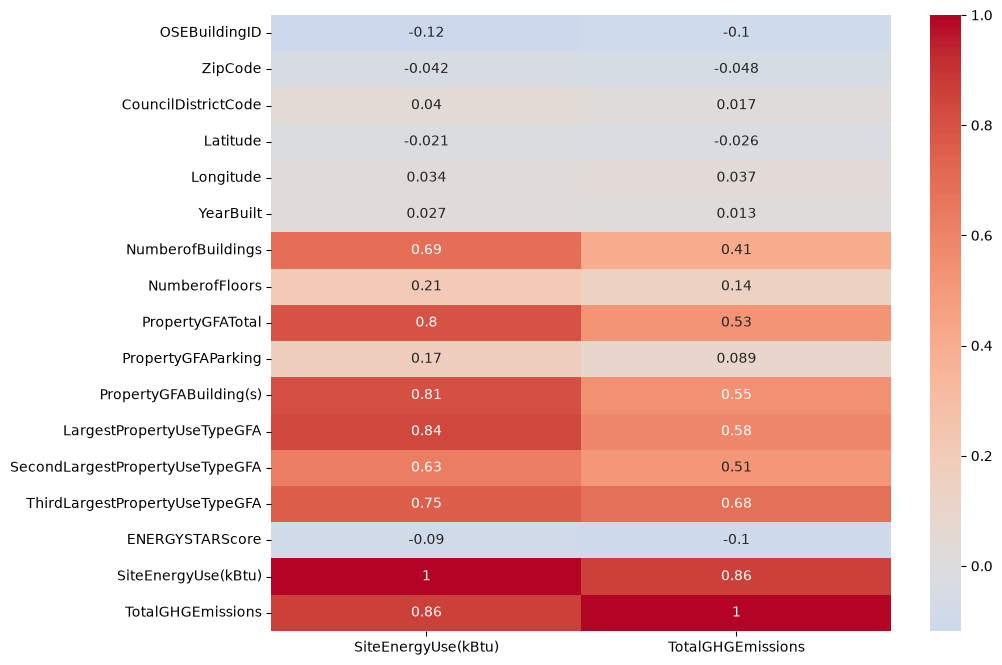

In [21]:
# détermination de la corrélation entre les colonnes numériques et les colonnes SiteEnergyUse(kBtu) et TotalGHGEmissions

corr_matrix = df_tri2.select_dtypes(include=['float64', 'int64']).corr()[['SiteEnergyUse(kBtu)','TotalGHGEmissions']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

Colonnes avec une corrélation modérée à forte (>0.4) avec SiteEnergyUse(kBtu): 
    - NumberOfBuildings
    - PropertyGFATotal
    - PropertyGFABuilding(s)
    - LargestPropertyUseTypeGFA
    - SecondLargestPropertyUseTypeGFA
    - ThirdLargestPropertyUseTypeGFA

TotalGHGEEmissions est une cible à prédire donc on ne la prends pas en compte
Le ENERGYSTARScore n'a pas une corrélation importante mais le but est aussi de voir son importance

# Visualisations

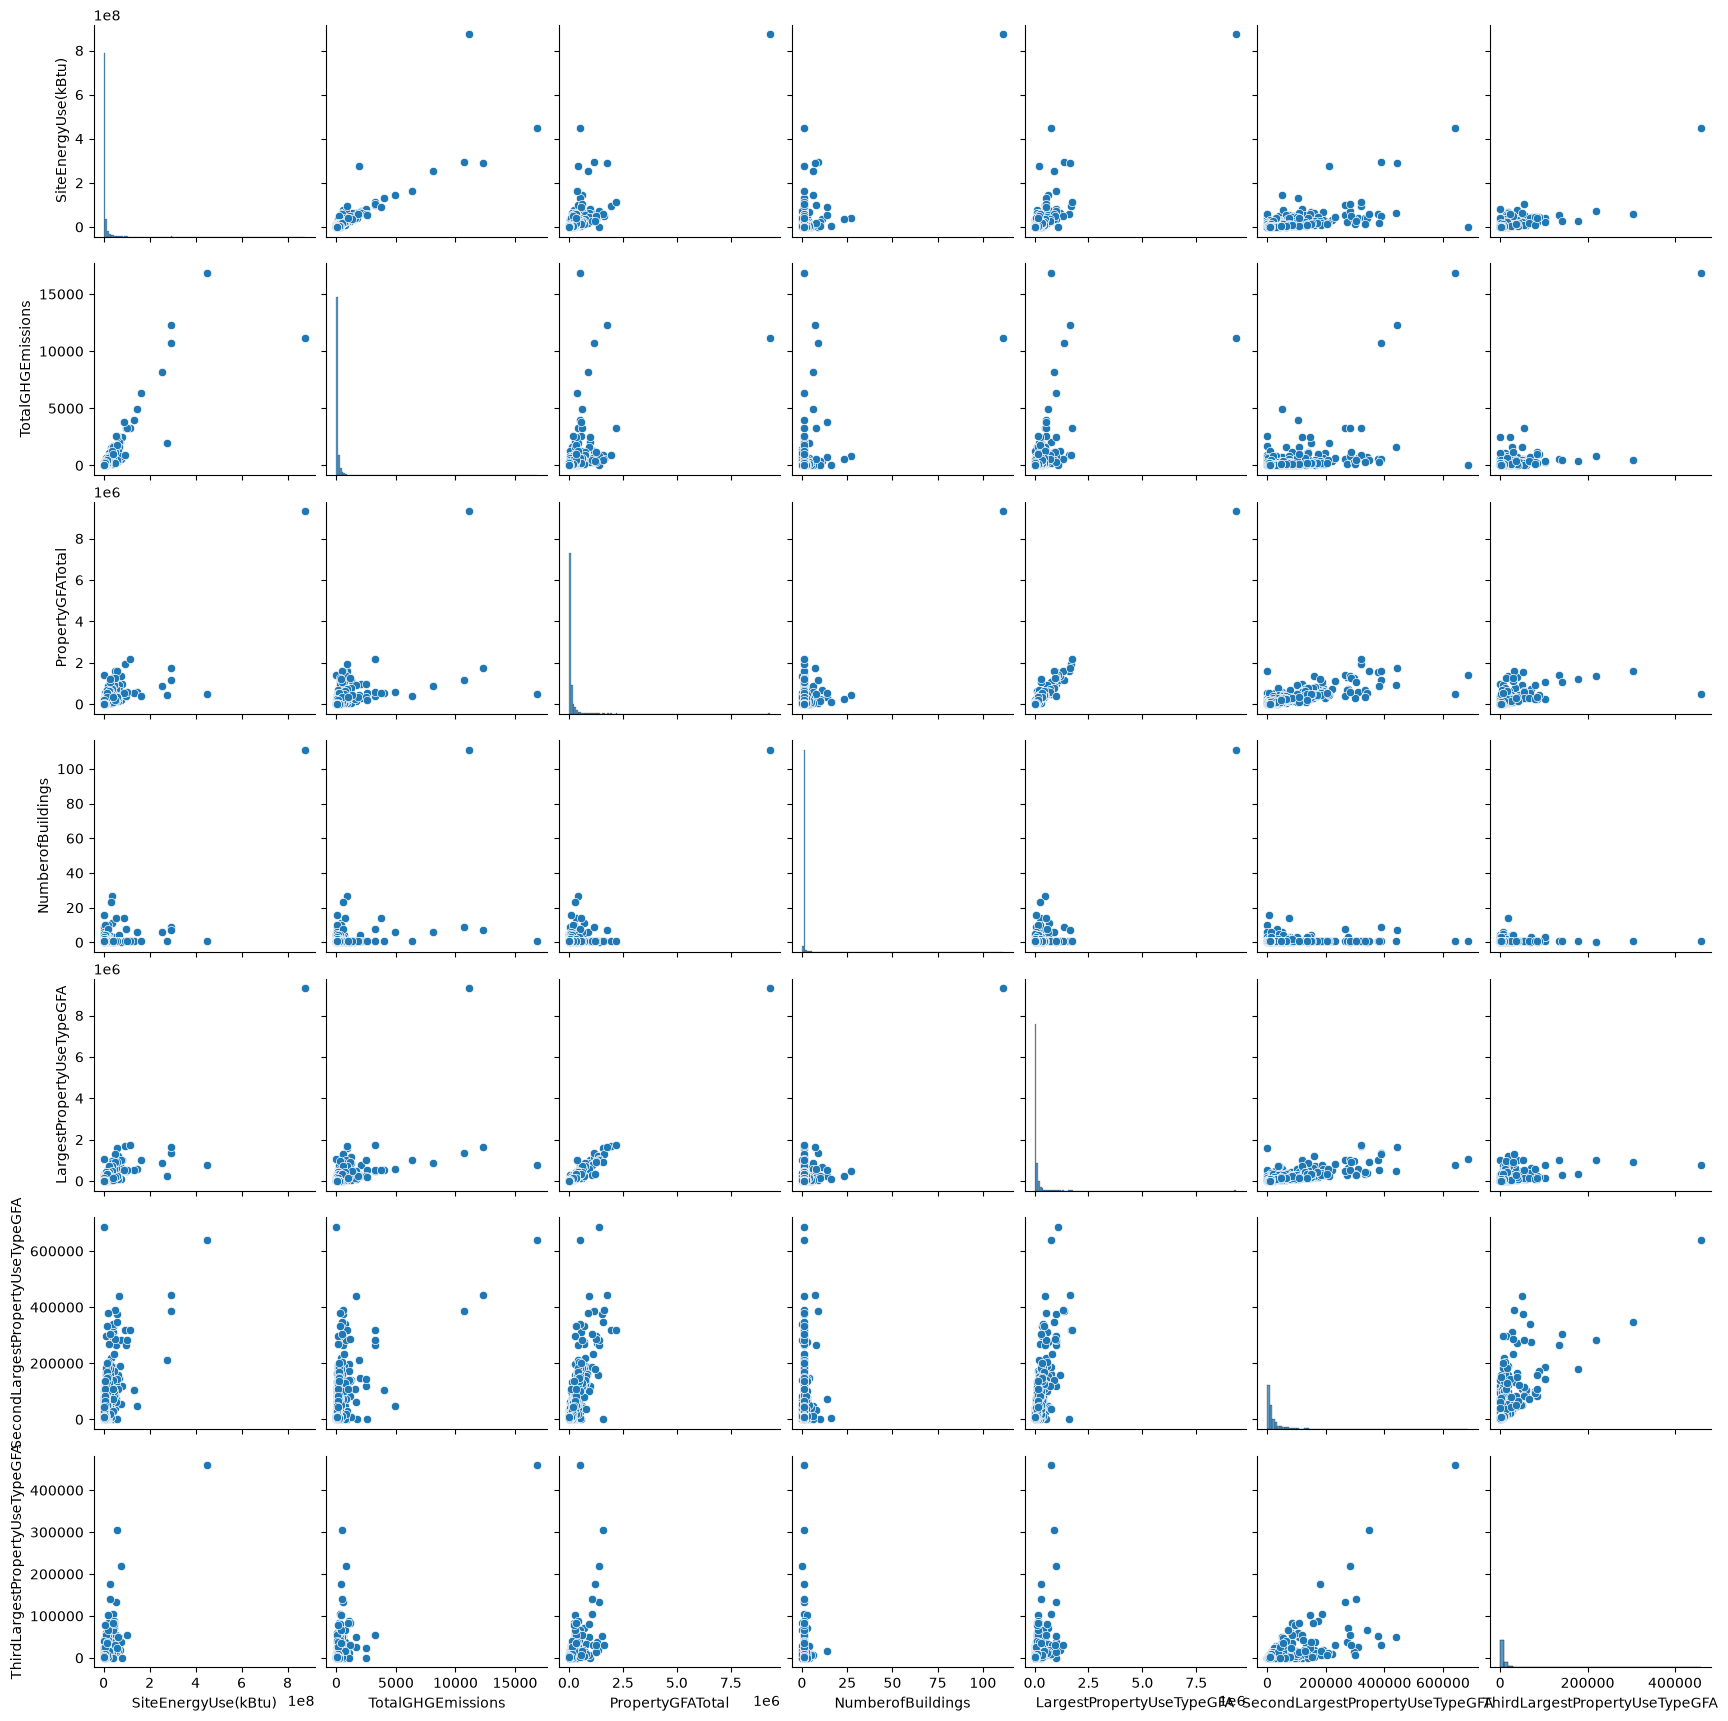

In [22]:
cols = [
    'SiteEnergyUse(kBtu)',
    'TotalGHGEmissions',
    'PropertyGFATotal',
    'NumberofBuildings',
    'LargestPropertyUseTypeGFA',
    'SecondLargestPropertyUseTypeGFA',
    'ThirdLargestPropertyUseTypeGFA'
]

sns.pairplot(df_tri2[cols])

plt.show()

In [23]:
# analyse de la colonne outliers
print("Valeurs et leur fréquence dans la colonne Outlier :")
print(df_tri2['Outlier'].value_counts())

#Il y a uniquement 32 valeurs au total, on peut considerer les autres comme des valeurs normales. On peut donc remplacer les valeurs manquantes par "No outlier"

df_tri3 = df_tri2.copy()
df_tri3['Outlier'] = df_tri3['Outlier'].fillna('No outlier')

print("Valeurs et leur fréquence dans la colonne Outlier après fillna:")
print(df_tri3['Outlier'].value_counts())

Valeurs et leur fréquence dans la colonne Outlier :
Outlier
Low outlier     23
High outlier     9
Name: count, dtype: int64
Valeurs et leur fréquence dans la colonne Outlier après fillna:
Outlier
No outlier      3344
Low outlier       23
High outlier       9
Name: count, dtype: int64


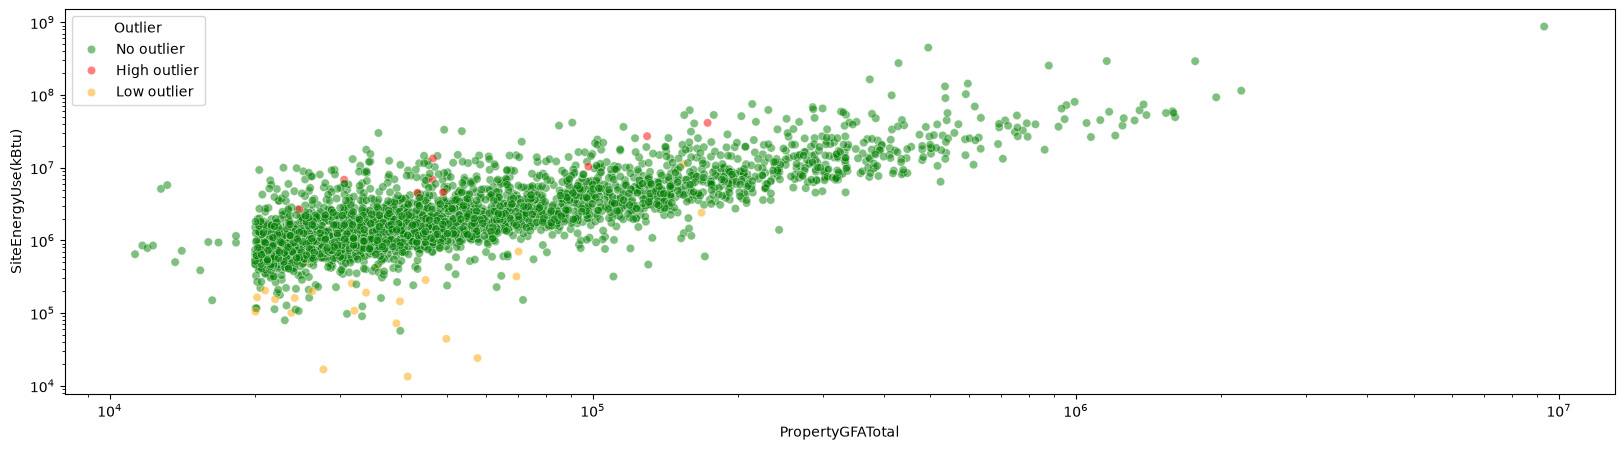

In [24]:
# Visualisation des outliers signalés dans la colonne Outlier par rapport à la surface totale et l'énergie consommée

plt.figure(figsize=(20, 5))

sns.scatterplot(data=df_tri3, x='PropertyGFATotal', y='SiteEnergyUse(kBtu)', hue='Outlier', palette={'Low outlier': 'orange', 'High outlier': 'red','No outlier': 'green' },alpha=0.5)
plt.xscale('log')
plt.yscale('log')

plt.show()

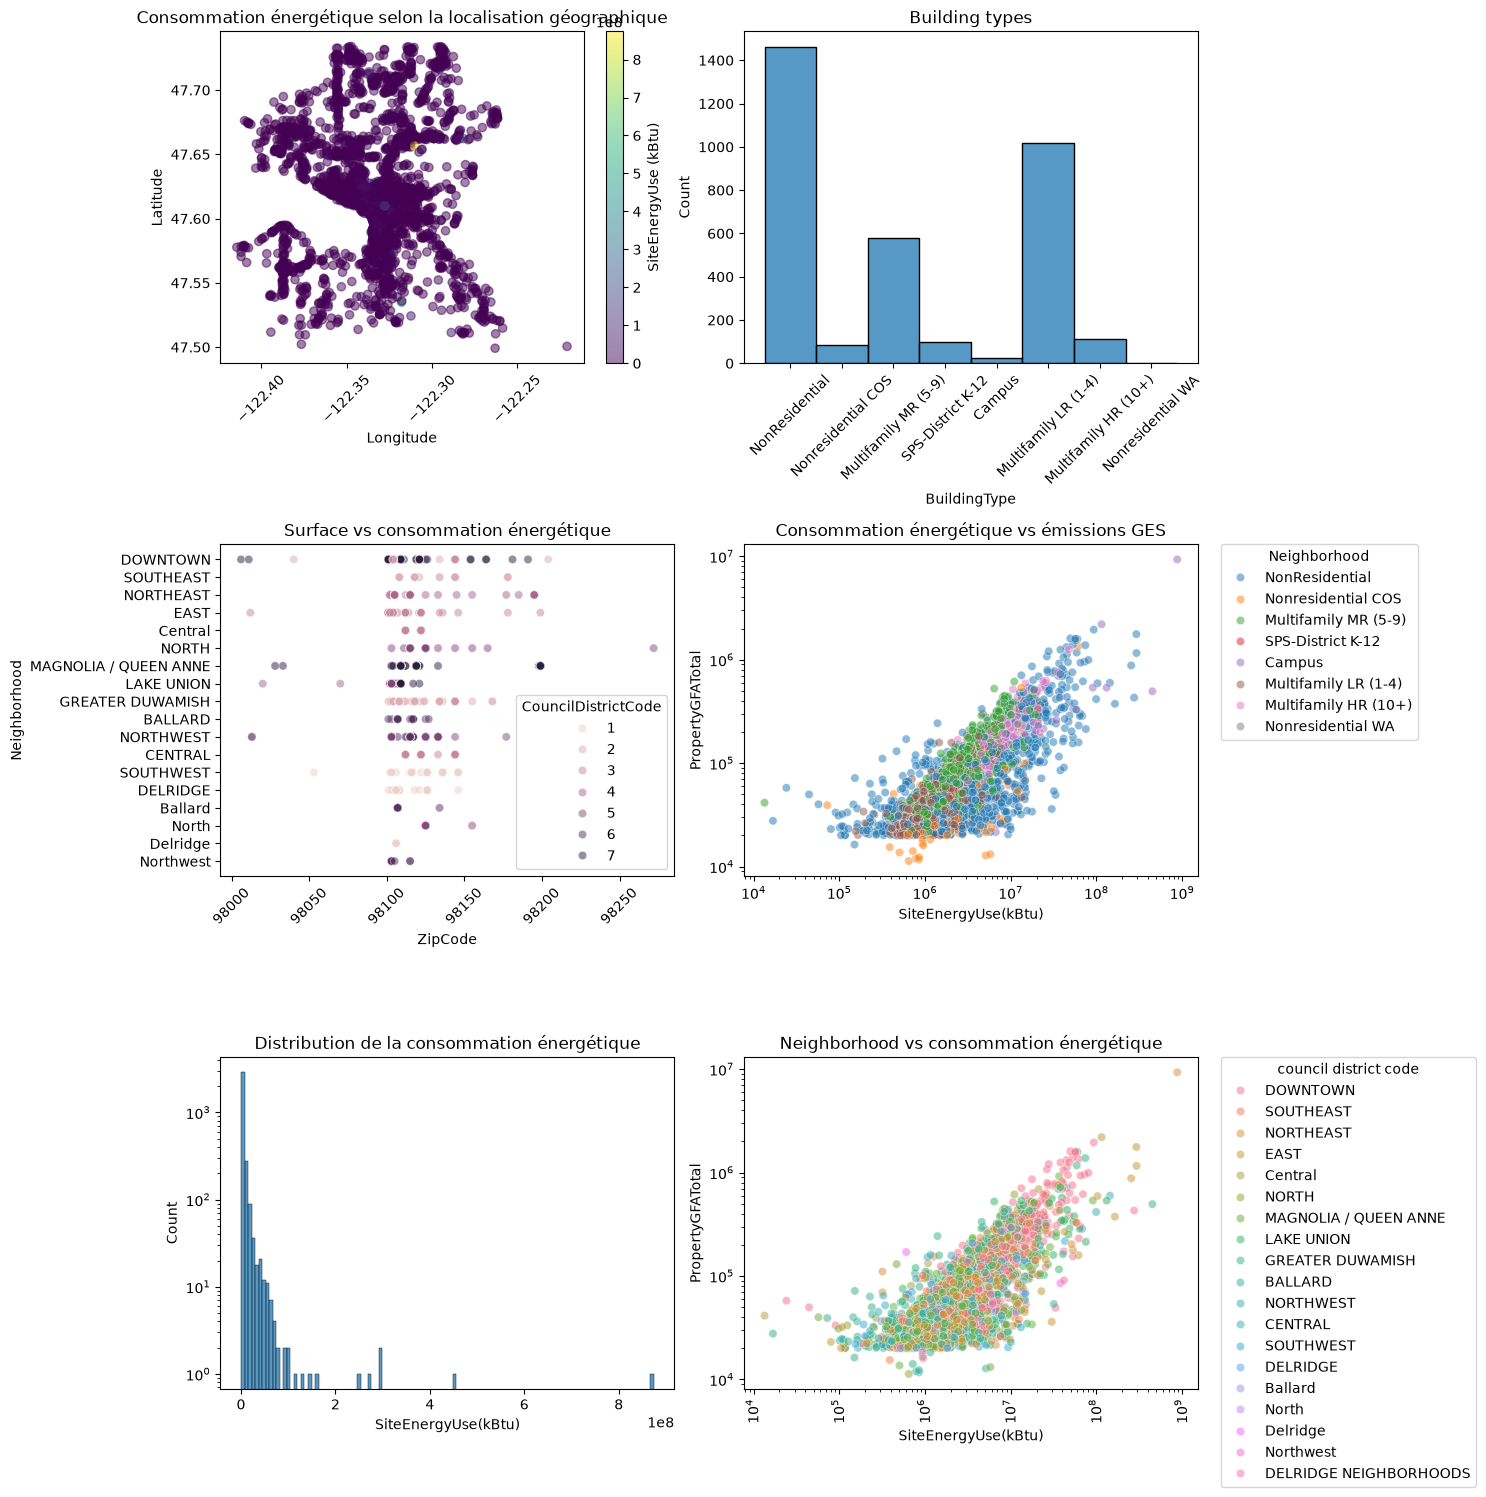

In [79]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

# Graphique 1 : Consommation énergétique selon la localisation géographique

scatter = axes[0, 0].scatter(
    df_tri3['Longitude'],
    df_tri3['Latitude'],
    c=df_tri3['SiteEnergyUse(kBtu)'],
    cmap='viridis',
    alpha=0.5
)

# Barre de couleur continue
fig.colorbar(
    scatter,
    ax=axes[0, 0],
    label='SiteEnergyUse (kBtu)'
)

axes[0, 0].set_title(
    'Consommation énergétique selon la localisation géographique'
)

axes[0, 0].set_xlabel('Longitude')
axes[0, 0].set_ylabel('Latitude')

# Graphique 2 : Distribution des building types
sns.histplot(
    data=df_tri3,
    x='BuildingType',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Building types')

# Graphique 3 : Building Type et consommation énergétique
sns.scatterplot(
    data=df_tri3,
    x='ZipCode',
    y='Neighborhood',
    hue = 'CouncilDistrictCode',
    alpha=0.5,
    ax=axes[1, 0],
)

axes[1, 0].set_title('Surface vs consommation énergétique')

# Graphique 4 : Energie, surface et Type de batiment
sns.scatterplot(
    data=df_tri3,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'BuildingType',
    ax=axes[1, 1],
    alpha=0.5
)
axes[1, 1].set_xscale('log')
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Consommation énergétique vs émissions GES')
axes[1, 1].legend(title='Neighborhood',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

# Graphique 5 : Energie, surface et Type de batiment
sns.histplot(
    data=df_tri3,
    x='SiteEnergyUse(kBtu)',
    ax=axes[2, 0]
)
axes[2, 0].set_title('Distribution de la consommation énergétique')
axes[2, 0].set_yscale('log')

# Graphique 6 : Neighborhood et consommation énergétique
sns.scatterplot(
    data=df_tri3,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'Neighborhood',
    alpha=0.5,
    ax=axes[2, 1],
)
axes[2, 1].set_title('Neighborhood vs consommation énergétique')
axes[2, 1].set_xscale('log')
axes[2, 1].set_yscale('log')
axes[2, 1].legend(title='council district code',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

axes[0, 0].tick_params(axis='x', labelrotation=45)
axes[0, 1].tick_params(axis='x', labelrotation=45)
axes[1, 0].tick_params(axis='x', labelrotation=45)
axes[2, 1].tick_params(axis='x', labelrotation=90)

plt.tight_layout()
plt.show()


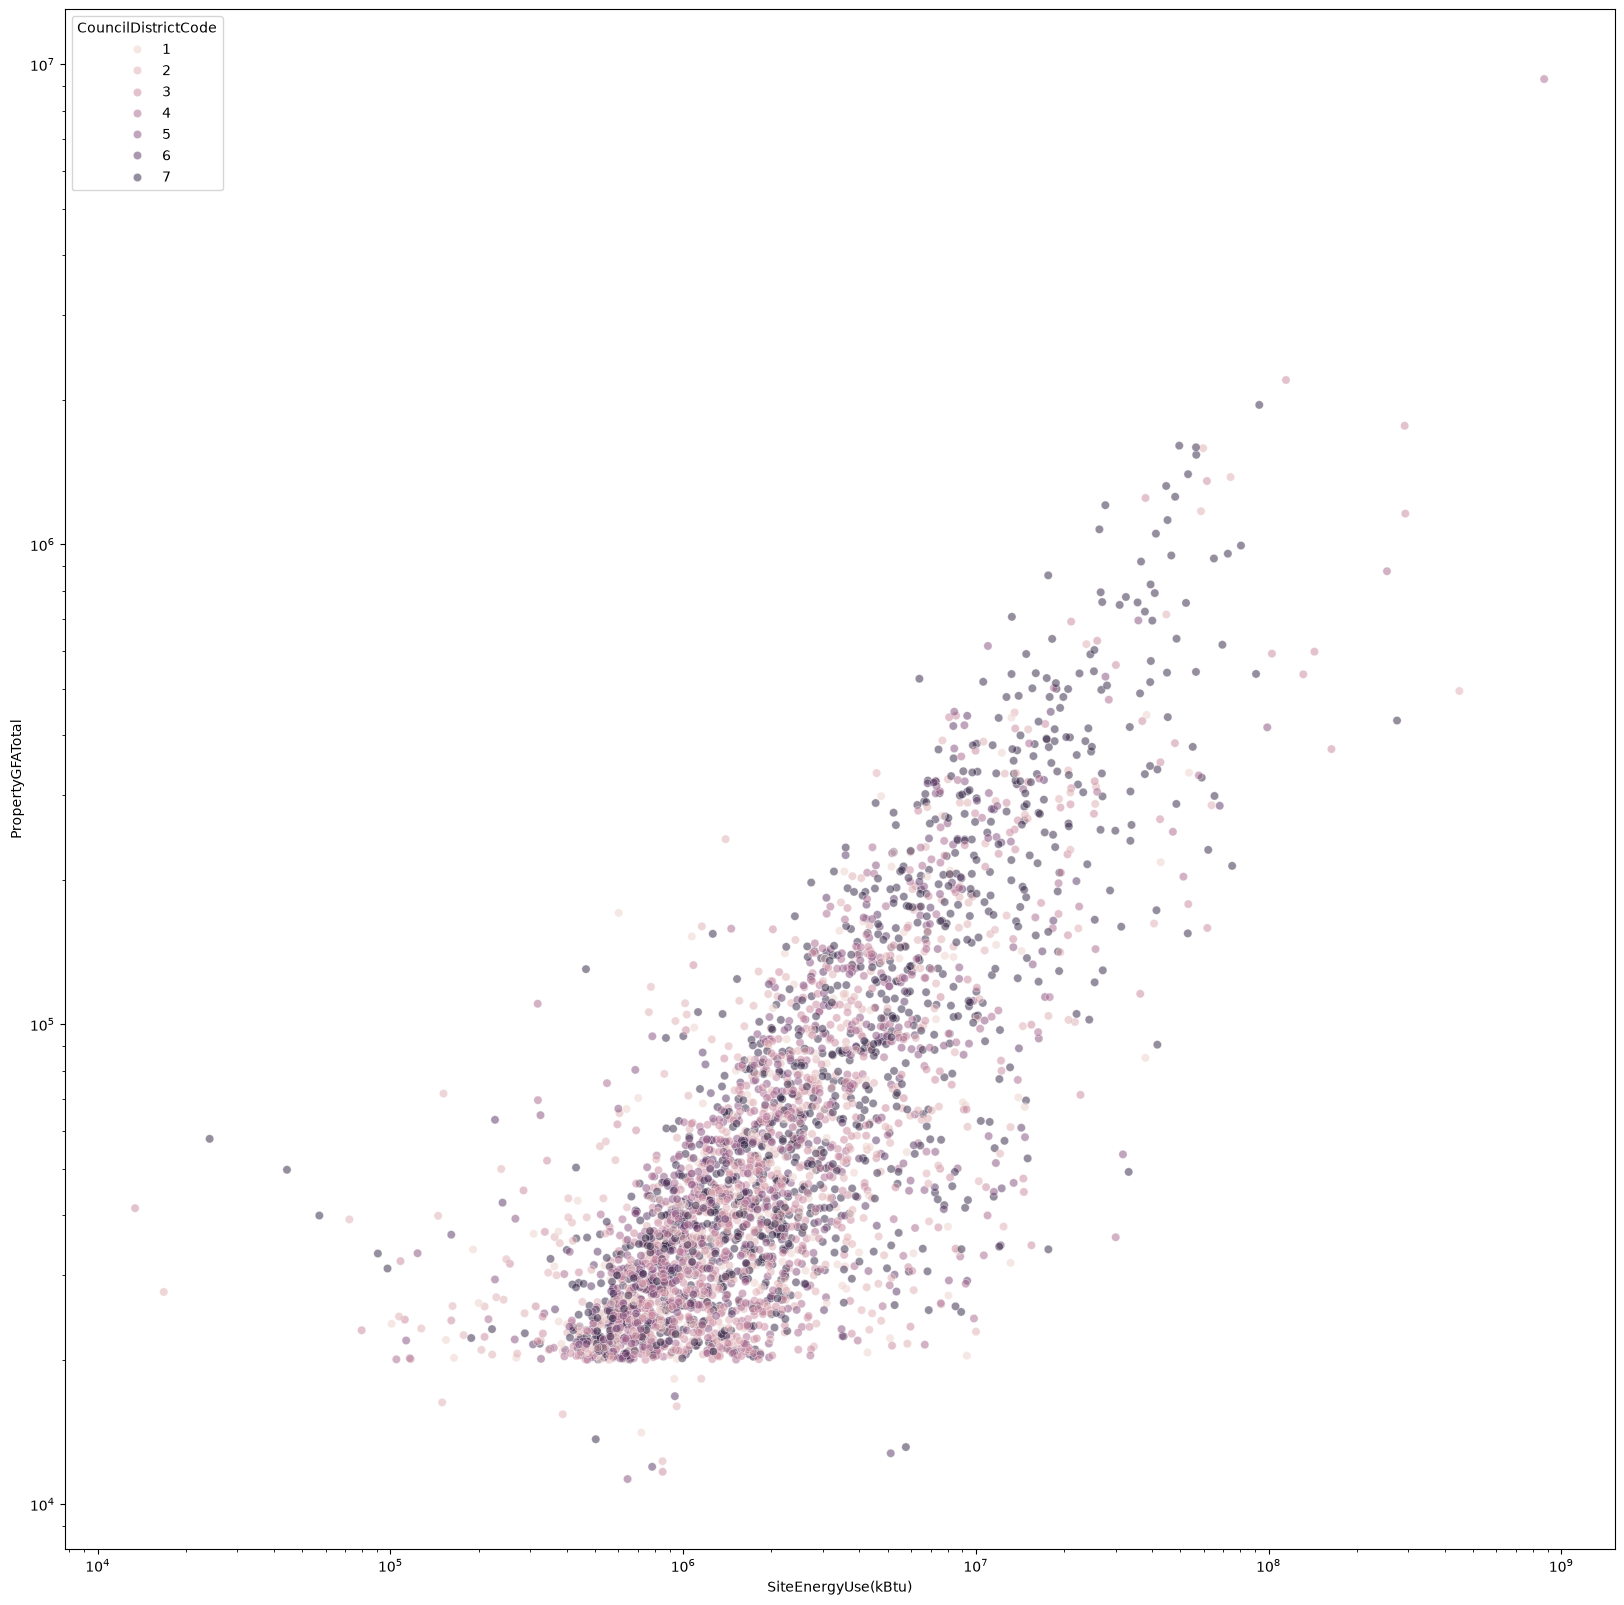

In [86]:
plt.figure(figsize=(20,20))

ax =sns.scatterplot(
    data=df_tri3,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'CouncilDistrictCode',
    alpha=0.5
)
ax.set_xscale('log')
ax.set_yscale('log')

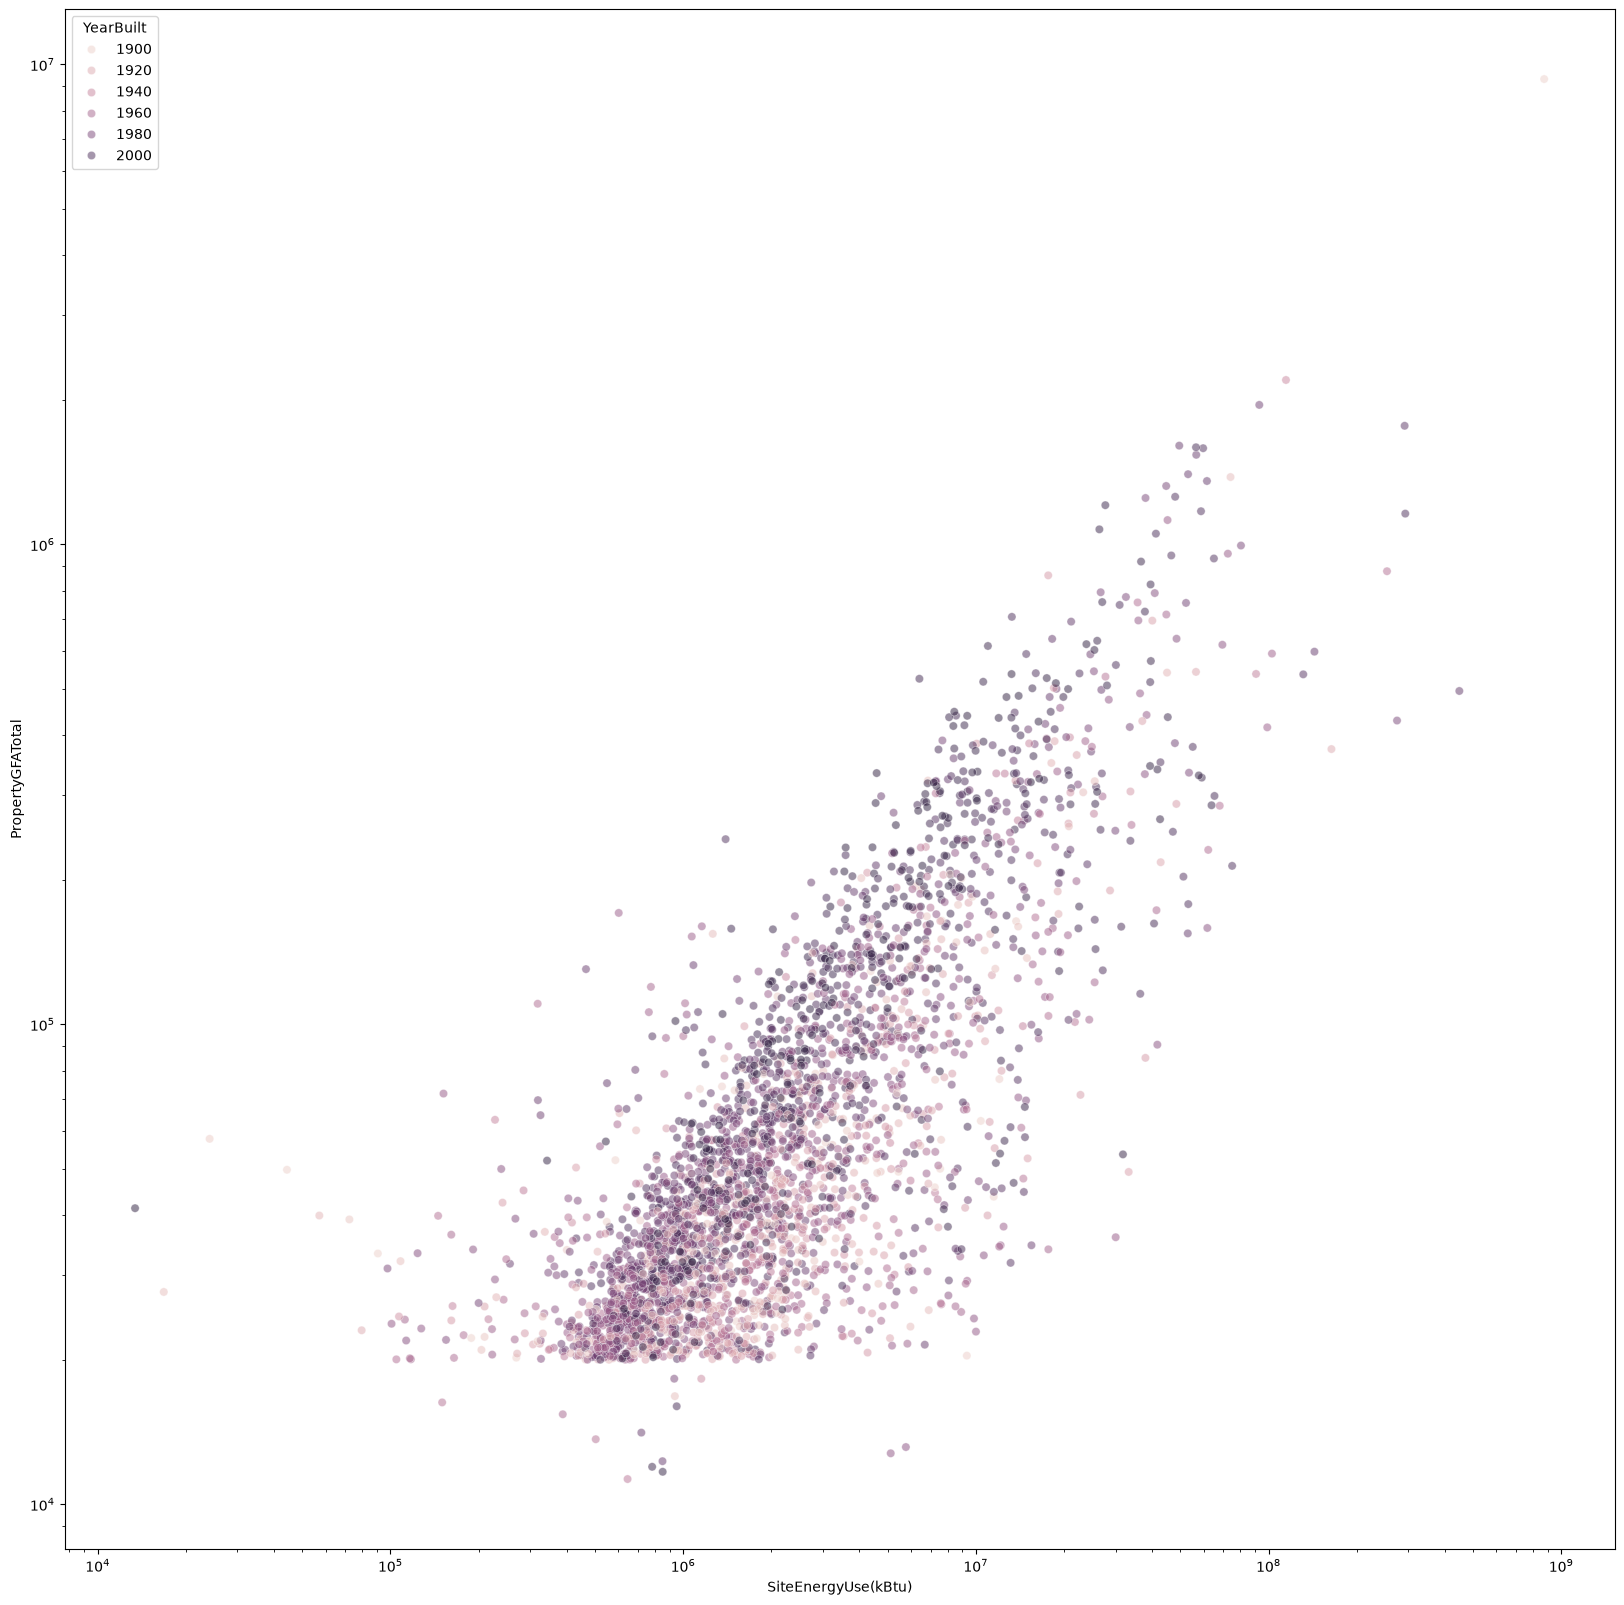

In [89]:
plt.figure(figsize=(20,20))

ax =sns.scatterplot(
    data=df,
    x='SiteEnergyUse(kBtu)',
    y='PropertyGFATotal',
    hue = 'YearBuilt',
    alpha=0.5
)
ax.set_xscale('log')
ax.set_yscale('log')

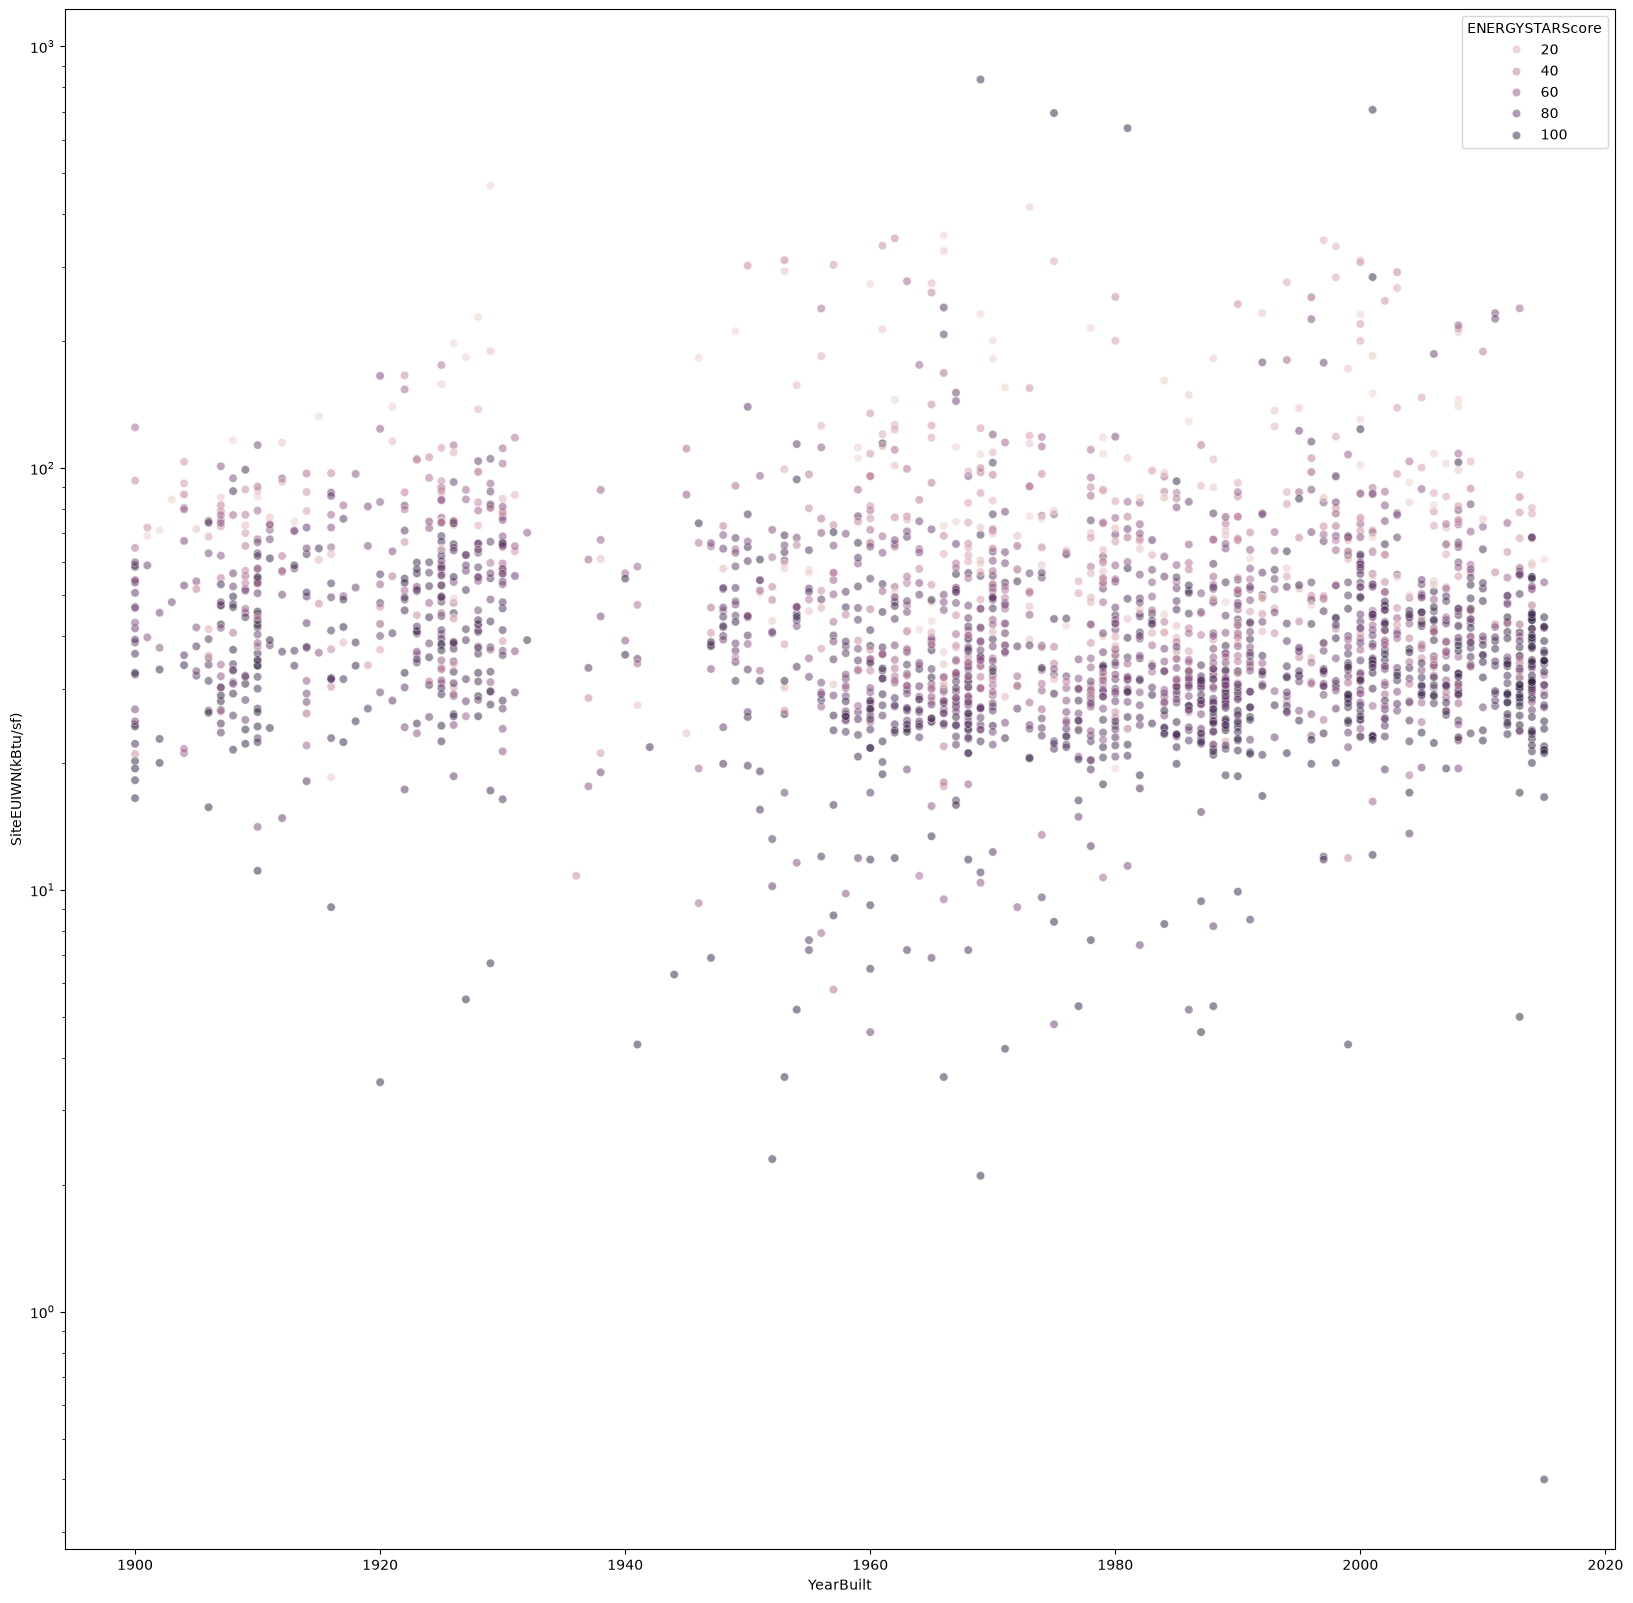

In [91]:
plt.figure(figsize=(20,20))

ax =sns.scatterplot(
    data=df,
    x='YearBuilt',
    y='SiteEUIWN(kBtu/sf)',
    hue = 'ENERGYSTARScore',
    alpha=0.5
)
ax.set_yscale('log')

Quelques conclusions : 

- Il y a des types de bâtiments autre que non-résidentiels dans le dataset --> supprimer les lignes "multifamily

- Il a des valeurs énergétiques à 0 --> à vérifier

- Il y a quelques outliers niveau consommation d'énergie qui remontent la moyenne fortement ( > 4.10^8 kBtu ) --> A supprimer ?

- Zipcode / Neigborhood / CouncilDistricCode , il n'y a pas vraiment de clusters bien définis qui se dégagent

- Year built semble avoir une légère corrélaton, pas directement avec la totalité de l'énergie mais l'énergie par la surface. 
    


In [ ]:
# check des valeurs énergétiques nulles
df_tri3[df_tri3['SiteEnergyUse(kBtu)'] <= 0]

# On remarque que les valeurs nulles correspondent à une ComplianceStatus de "Missing Data"

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,...,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEnergyUse(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions
28,34,SPS-District K-12,K-12 School,Meany Building,301/300 21st Ave. E.,98112.0,0688000090,3,Central,47.62266,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,0.00
31,37,SPS-District K-12,K-12 School,John Hay Elementary,201 Garfield St.,98109.0,0809000005,7,MAGNOLIA / QUEEN ANNE,47.63290,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,10.43
62,87,SPS-District K-12,K-12 School,Arbor Heights Elementary,3701 S.W. 104th St.,98146.0,2518400005,1,SOUTHWEST,47.50970,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,4.19
81,118,SPS-District K-12,K-12 School,Pathfinder K-8,1901 SW Genesee St.,98106.0,1324039116,1,DELRIDGE,47.56360,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,11.84
85,122,SPS-District K-12,K-12 School,John Muir Elementary,3301 S. Horton St.,98144.0,1524049002,2,SOUTHEAST,47.57324,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,16.36
95,140,SPS-District K-12,K-12 School,B.F. Day Elementary,3921 Linden Ave. N.,98103.0,1931301145,6,LAKE UNION,47.65464,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,14.67
133,217,SPS-District K-12,K-12 School,Whitman Middle,9201 15th Ave. NW.,98117.0,3526039131,6,BALLARD,47.69675,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,229.38
139,227,SPS-District K-12,K-12 School,Washington Middle,2101 S. Jackson,98144.0,3646100540,3,CENTRAL,47.59796,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,170.90
152,242,SPS-District K-12,K-12 School,Olympic View Elementary,504 N.E. 95th St.,98115.0,5100404840,5,NORTH,47.69823,...,NaN,NaN,NaN,NaN,NaN,0.0,False,Missing Data,No outlier,0.00
304,435,NonResidential,Other,Washington State Convention Center,705 Pike St,98101.0,1978200105,7,DOWNTOWN,47.61195,...,686750.0,NaN,NaN,NaN,NaN,0.0,False,Non-Compliant,No outlier,0.00


In [ ]:
# Quantité de valeurs par ComplianceStatus --> on peut supprimer les lignes avec "Missing Data"
df_tri3["ComplianceStatus"].value_counts()

ComplianceStatus
Compliant                       3211
Error - Correct Default Data     113
Non-Compliant                     37
Missing Data                      15
Name: count, dtype: int64

In [ ]:
# Les compliance-status "Error - Correct Default Data" correspondent à DefaultData = True. Est-ce qu'on garde ces valeurs ou non ? 

df_tri3[df_tri3["DefaultData"]== True] 

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,...,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEnergyUse(kBtu),DefaultData,ComplianceStatus,Outlier,TotalGHGEmissions
22,28,SPS-District K-12,K-12 School,Graham Hill Elementary,5149 S. Graham St.,98118.0,1102000138,2,SOUTHEAST,47.545760,...,NaN,NaN,NaN,NaN,95.0,1.539478e+06,True,Error - Correct Default Data,No outlier,38.53
30,36,SPS-District K-12,K-12 School,Jane Addams Middle,11051 34th Ave. N.E.,98125.0,0752000170,5,NORTH,47.709940,...,NaN,NaN,NaN,NaN,75.0,6.779173e+06,True,Error - Correct Default Data,No outlier,270.18
38,51,SPS-District K-12,K-12 School,Eckstein Middle,3003 N.E. 75th St.,98115.0,0425049022,4,NORTHEAST,47.682520,...,NaN,NaN,NaN,NaN,88.0,6.399128e+06,True,Error - Correct Default Data,No outlier,266.05
86,125,SPS-District K-12,K-12 School,Mercer International Middle,1600 Columbian Way S.,98108.0,1624049214,2,GREATER DUWAMISH,47.564130,...,NaN,NaN,NaN,NaN,61.0,6.456026e+06,True,Error - Correct Default Data,No outlier,238.48
87,127,SPS-District K-12,K-12 School,Orca K-8 School,5215 46th Ave. S.,98118.0,1704900242,2,SOUTHEAST,47.554780,...,NaN,NaN,NaN,NaN,93.0,1.633399e+06,True,Error - Correct Default Data,No outlier,20.48
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,29069,Multifamily LR (1-4),Senior Care Community,Lakeshore,11448 Rainier Ave S,98178.0,1180001715,3,EAST,47.500619,...,132284.0,NaN,NaN,NaN,98.0,6.723972e+06,True,Error - Correct Default Data,No outlier,157.88
3126,39332,SPS-District K-12,K-12 School,South Shore K-8,4800 S. Henderson,98118.0,2123700250,2,SOUTHEAST,47.523740,...,NaN,NaN,NaN,NaN,84.0,4.959298e+06,True,Error - Correct Default Data,No outlier,124.77
3366,50210,Nonresidential COS,Office,Central West HQ / Brown Bear,1403 w howe,NaN,2425039137,7,MAGNOLIA / QUEEN ANNE,47.635720,...,NaN,NaN,NaN,NaN,75.0,5.026677e+05,True,Error - Correct Default Data,No outlier,3.50
3369,50220,Nonresidential COS,Office,Genesee/SC SE HQ,4420 S Genesee,NaN,4154300585,2,SOUTHEAST,47.564400,...,NaN,NaN,NaN,NaN,93.0,3.878100e+05,True,Error - Correct Default Data,No outlier,7.79


# Analyse de ENERGYSTARScore

<Axes: >

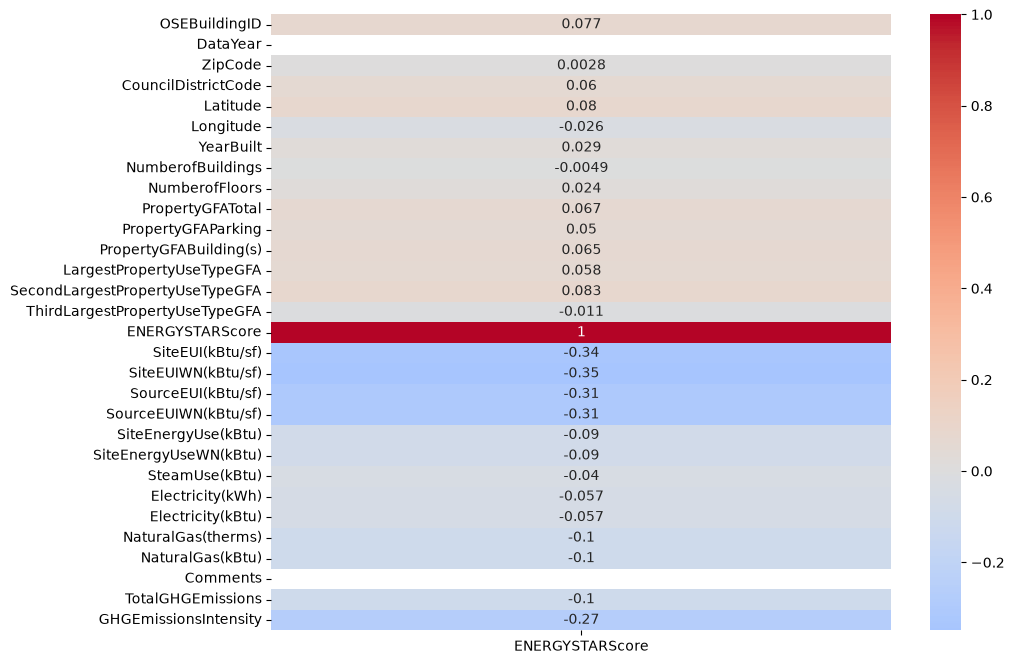

In [26]:
# détermination de la corrélation entre les colonnes numériques et le ENERGYSTARScore

corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()[['ENERGYSTARScore']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

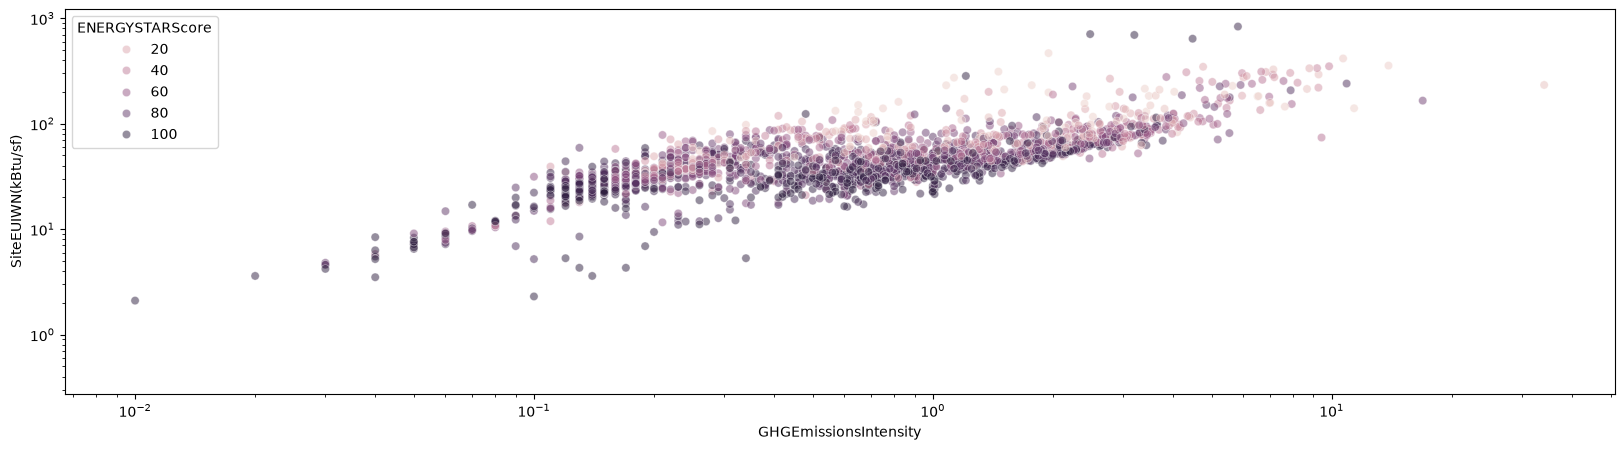

In [27]:
# visualisation du score ENERGYSTAR par rapport à l'énergie consommée et les émissions de GES

plt.figure(figsize=(20, 5))

sns.scatterplot(data=df, x='GHGEmissionsIntensity', y='SiteEUIWN(kBtu/sf)', hue='ENERGYSTARScore',alpha=0.5)
plt.xscale('log')
plt.yscale('log')

plt.show()

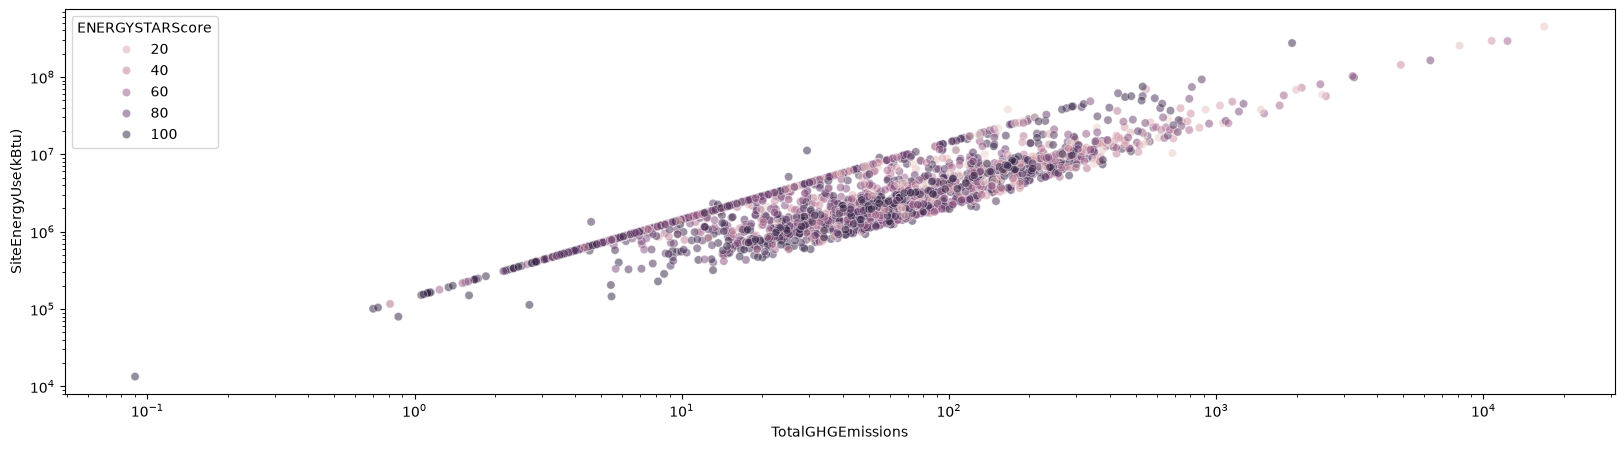

In [28]:
# visualisation du score ENERGYSTAR par rapport à l'énergie consommée et les émissions de GES

plt.figure(figsize=(20, 5))

sns.scatterplot(data=df_tri3, x='TotalGHGEmissions', y='SiteEnergyUse(kBtu)', hue='ENERGYSTARScore',alpha=0.5)
plt.xscale('log')
plt.yscale('log')

plt.show()

On voit une tendance par rapport à la notation ENERGYSTARScore, mais uniquement dans le cas de l'énergie et émissions par surface, et non pas par rapport à l'énergie et émissions totales. Sachant que nous estimons avoir accès aux données de surface, l'utilisation du ENERYSTARScore semble pertinant pour entrainer les modèles

# Nettoyage officiel

In [ ]:
df_clean = df[["BuildingType","SiteEnergyUse(kBtu)","PropertyGFATotal","YearBuilt","ENERGYSTARScore"]]

df_clean.head()

,SiteEnergyUse(kBtu),PropertyGFATotal,YearBuilt,ENERGYSTARScore
0,7226362.5,88434,1927,60.0
1,8387933.0,103566,1996,61.0
2,72587024.0,956110,1969,43.0
3,6794584.0,61320,1926,56.0
4,14172606.0,175580,1980,75.0
